# Exercise 1
Nico Reiterer - 5191 2112

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 1.1. - Approximation of the integral

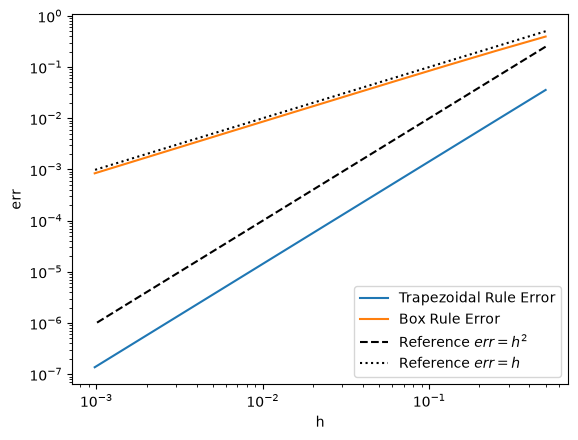

In [16]:
def T(h: float, f: callable) -> float:
    """
    Implementation of the trapezoidal rule for numerical integration.
    """
    N = round(1 / h)

    # x_i = i * h
    x = np.arange(0, N+1) * h # N + 1 because the last point is i + 1, so not N-1, but N ..

    y = f(x)
    h = 1 / N

    
    return h * (0.5 * y[0] + y[1:-1].sum() + 0.5 * y[-1])

def R(h: float, f:callable) -> float:
    """
    IMplementation of the box rule for numerical integration.
    """
    N = round(1 / h)

    # x_i = i * h
    x = np.arange(0, N) * h

    y = f(x)
    h = 1 / N
    
    return h * y.sum()

def f(x: np.ndarray) -> np.ndarray:
    """
    Function to be integrated in 1b.
    """
    return np.exp(x)

def N(i: int) -> float:
    return 2 ** (i + 1)

def calc_1b_error(h: np.ndarray, f: callable, appr: callable) -> np.ndarray:
    """
    Calculate the error for the trapezoidal rule.
    """

    err = np.zeros_like(h)
    for i in range(len(h)):
        err[i] = np.exp(1) - 1 - appr(h[i], f)

    return err

h = 1 / N(np.arange(0, 10))
plt.loglog(h, np.abs(calc_1b_error(h, f, T)), label="Trapezoidal Rule Error")
plt.loglog(h, np.abs(calc_1b_error(h, f, R)), label="Box Rule Error")
plt.loglog(h, h**2, "k--", label="Reference $err = h^2$")
plt.loglog(h, h, "k:", label="Reference $err = h$")
plt.xlabel("h")
plt.ylabel("err")
plt.legend()
plt.show()

**Does the true error behave like $Ch^2$?**

Yes, the true error behaves like $Ch^2$ for the trapezoidal rule. The error decreases quadratically as the step size $h$ decreases, which is I guess consistent with the theory!

**Do the same thing for the box rule as well. What error behaviour do you see?**

We see a linear decrease in the error as the step size $h$ decreases.

## 1.2. - Design of an error estimator

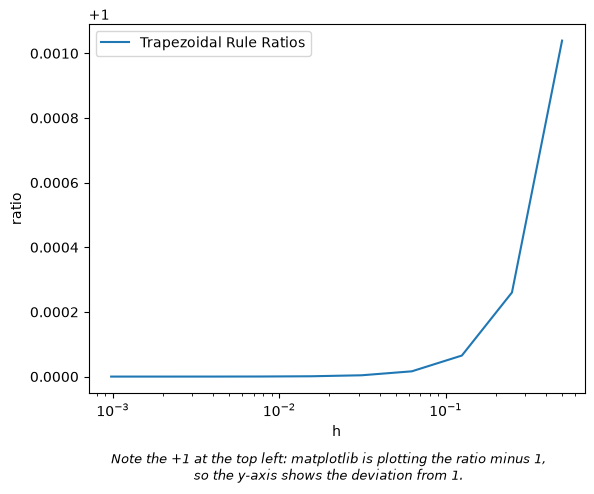

In [3]:
# a) Making the Ansatz
def C(h: float, f: callable, T: callable) -> float:
    """
    Calculate the constant C for the trapezoidal rule.
    """
    y = 1 / h**2 * 4 / 3 * (T(h/2, f) - T(h, f))
    return y

def E(h: float, f: callable, T: callable) -> float:
    """
    Calculate the error for the trapezoidal rule, which is C * h^2, hence taking the same as above but w/out the 1/h^2 factor.
    """
    y = 4 / 3 * (T(h/2, f) - T(h, f))
    return y

# b) Computing the ratios r(i) := err(i) / E(h(i))
def calc_ratios(h: np.ndarray, f: callable, appr: callable) -> np.ndarray:
    """
    Calculate the ratios of the true error to estimated error: 
        r(i) := err(i) / E(h(i)) for the trapezoidal rule.
    """

    err = calc_1b_error(h, f, appr)
    E_vals = np.array([E(h_i, f, appr) for h_i in h])
    return err / E_vals

h = 1 / N(np.arange(0, 10))
plt.semilogx(h, calc_ratios(h, f, T), label="Trapezoidal Rule Ratios")
plt.xlabel("h")
plt.ylabel("ratio")
plt.figtext(
    0.5, -0.01,
    "Note the +1 at the top left: matplotlib is plotting the ratio minus 1,\n"
    "so the y-axis shows the deviation from 1.",
    ha="center", va="top", fontsize=9, style="italic",
)
plt.legend()
plt.show()

So we can see quite cleary that the smaller h gets (so the bigger N gets), the smaller the ratio of the actual error to the estimated error gets!

## 1.3. - Some functions to inspect

In [4]:
def f_1(C: float, h: float, alpha: float) -> float:
    """
    Function 1 from 1.3. h -> C * h ** alpha 
        >> Here I expect a straight line in the log-log plot, with slope alpha.
    """
    return C * h**alpha

def f_2(C: float, N: float, b: float) -> float:
    """
    Function 2 from 1.3. N -> C * exp(-b * N)
        >> Here I expect a straight line in the semi-logy plot, with slope -b.
    """
    return C * np.exp(-b * N)

def f_3(C: float, h: float, b: float) -> float:
    """
    Function 3 from 1.3. h -> C * exp(-b / h)
        >> Here you can see that ln f is not linear in h or in ln h, but in 1/h 
    """
    return C * np.exp(-b / h)

def f_4(C: float, h: float, b: float) -> float:
    """
    Function 4 from 1.3. h -> C * exp(-b / h**2)
        >> So this is similar to f_3, but now the slope is -b in 1/h**2, so we expect a straight line in the semi-logy plot of f against 1/h**2.
    """
    return C * np.exp(-b / h**2)



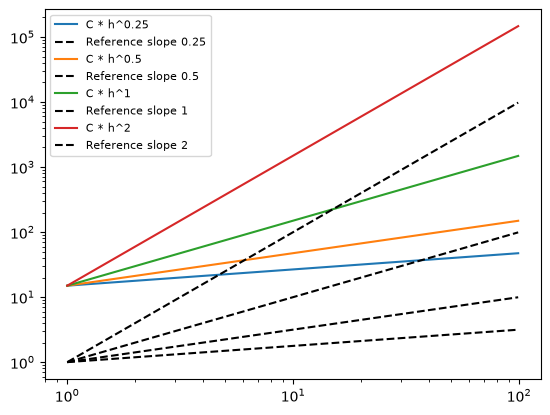

In [5]:
h = np.arange(1, 100)
for i in [0.25, 0.5, 1, 2]:
    plt.loglog(h, f_1(15, h, i), label=f"C * h^{i}")
    
    # plotting the slope which is essentially just based on the alpha...
    # taking the log of both sides gives us log(f) = log(C) + alpha * log(h), so the slope is alpha.
    plt.loglog(h, h**i, "k--", label=f"Reference slope {i}")

plt.legend(fontsize=8)
plt.show()

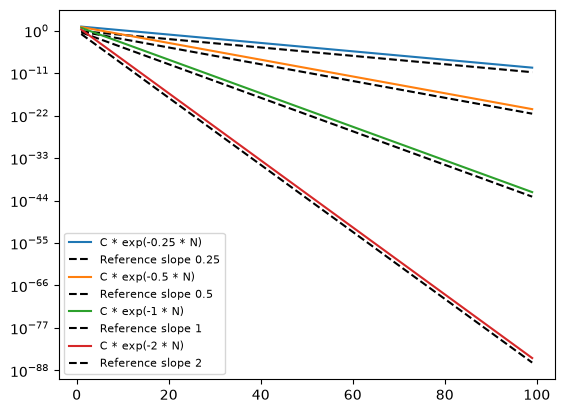

In [6]:
h = np.arange(1, 100)
for i in [0.25, 0.5, 1, 2]:
    plt.semilogy(h, f_2(15, h, i), label=f"C * exp(-{i} * N)")
    
    # plotting the slope which is essentially just based on the alpha...
    # taking the log of the y-axis gives us N -> log(f) = log(C) - b * N, so the slope is -b.
    plt.semilogy(h, np.exp(-i * h), "k--", label=f"Reference slope {i}")

plt.legend(fontsize=8)
plt.show()

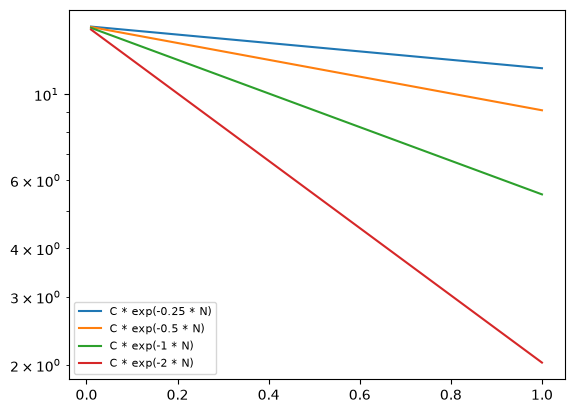

In [7]:
h = np.arange(1, 100)
for i in [0.25, 0.5, 1, 2]:
    plt.semilogy(1/h, f_3(15, h, i), label=f"C * exp(-{i} * N)")
    
    # Function 3 from 1.3. h -> C * exp(-b / h)
    # applying the log to both sides gives us log(f) = log(C) - b * 1/h, so the slope is -b if we plot log(f) against 1/h.

plt.legend(fontsize=8, loc="lower left")
plt.show()

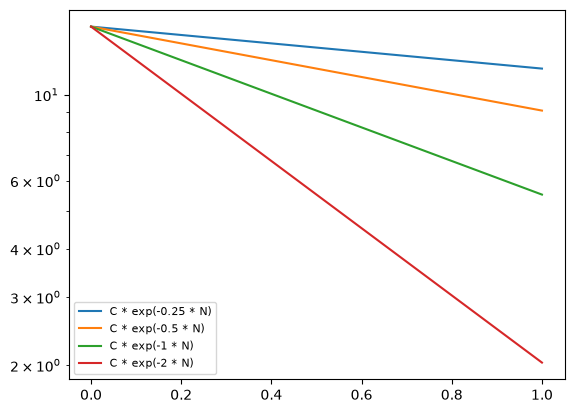

In [8]:
h = np.arange(1, 100)
for i in [0.25, 0.5, 1, 2]:
    plt.semilogy(1/h**2, f_4(15, h, i), label=f"C * exp(-{i} * N)")

    # Function 4 from 1.3. h -> C * exp(-b / h**2)
    # applying the log to both sides gives us log(f) = log(C) - b * 1/h**2, so the slope is -b if we plot log(f) against 1/h**2.

plt.legend(fontsize=8, loc="lower left")
plt.show()

## 1.4. - Interpolating polynomials

In [9]:
# a) Lagrange interpolation polynomial, note to myself: read through the exercise first and do not implement if actually not needed
def l_i(x: np.ndarray, x0: float) -> float:
    """
    Lagrange polynomial.
    """
    n = len(x)
    L = np.ones(n)
    for i in range(n):
        for j in range(n):
            L[i] *= (x0 - x[j]) / (x[i] - x[j]) if j != i else 1
    
    return L

def lagrange_interpolation(x: np.ndarray, y: np.ndarray, x0: float) -> float:
    """
    Lagrange interpolation p(x) = sum_{i=0}^{n} y_i * l_i(x)
    """
    return np.sum(y * l_i(x, x0))

**Data:** $(x_0, f_0) = (0, 0)$, $(x_1, f_1) = (1, 2)$, $(x_2, f_2) = (4, 8)$

**Lagrange basis polynomials:**

$$
\ell_0(x) = \frac{(x - x_1)(x - x_2)}{(x_0 - x_1)(x_0 - x_2)} = \frac{(x - 1)(x - 4)}{(0 - 1)(0 - 4)} = \frac{(x - 1)(x - 4)}{4}
$$

$$
\ell_1(x) = \frac{(x - x_0)(x - x_2)}{(x_1 - x_0)(x_1 - x_2)} = \frac{(x - 0)(x - 4)}{(1 - 0)(1 - 4)} = -\frac{x(x - 4)}{3}
$$

$$
\ell_2(x) = \frac{(x - x_0)(x - x_1)}{(x_2 - x_0)(x_2 - x_1)} = \frac{(x - 0)(x - 1)}{(4 - 0)(4 - 1)} = \frac{x(x - 1)}{12}
$$

**Interpolating polynomial in Lagrange form:**

$$
p(x) = \sum_{i=0}^{2} f_i \, \ell_i(x) = 0 \cdot \frac{(x - 1)(x - 4)}{4} + 2 \cdot \left(-\frac{x(x - 4)}{3}\right) + 8 \cdot \frac{x(x - 1)}{12}
$$



$$
= -\frac{2x(x - 4)}{3} + \frac{2x(x - 1)}{3} = \frac{2x}{3}\big[-(x - 4) + (x - 1)\big] = \frac{2x}{3} \cdot 3 
$$

$$
= 2x
$$


**Check:** $p(0) = 0$, $p(1) = 2$, $p(4) = 8$  >> nice

### 1.4. b
![alt text](ex1_14_b.jpg "Title")

In [10]:
### 1.4. c) Checking approximation p(2) using the numpy routines polyfit(x, f, n) and polyval.
print(np.polyfit([0, 1, 4], [0, 2, 8], 2))
print(np.polyval(np.polyfit([0, 1, 4], [0, 2, 8], 2), 2))

# Nice, same result who would have guessed...
try:
    np.testing.assert_almost_equal(np.polyval(np.polyfit([0, 1, 4], [0, 2, 8], 2), 2), 4.0, decimal=10)
except AssertionError as e:
    print(f"Assertion Error: {e}")

[5.26101768e-16 2.00000000e+00 2.60153413e-15]
4.000000000000001


## 1.5. - Interpolating polynomials II

### 1.5. a)
Write a routine that has as input the vectors x and f of knots and data (both vectors have
the length n+ 1) and returns the value of the interpolating polynomial at the point 0, i.e., p(0)
and the polynomial p of degree n satisfies p(xi) = fi for all i. To simplify matters, you may use
polyfit and polyval.

In [11]:
def routine(x: np.ndarray, f: np.ndarray) -> float:
    """
    Routine that has as input the vectors x and f of knots and data (both vectors have
    the length n + 1) and returns the value of the interpolating polynomial at the point 0, i.e., p(0)
    and the polynomial p of degree n satisfies p(xi) = fi for all i. To simplify matters, you may use
    polyfit and polyval.
    """
    coeffs = np.polyfit(x, f, len(x) - 1)
    return np.polyval(coeffs, 0)

### 1.5. b) + c)
Based on a), write a function whose input is a function handle f and integers m, n ∈ N0.
The output is a matrix N ∈R(m+1)×(n+1) with entries Nj,k := pj,k(0), where j = 0,...,m,
k = 0,...,n and pj,k is the polynomial of degree k that interpolates the data (hj+ℓ,f(hj+ℓ)),
ℓ= 0,...,k, where hi := 2−i

_Remark: This matrix N is the so-called Neville-scheme for interpolation although it is usually set
up differently. (This will be done later in class.)_

Then apply your routine of b) to the function
$f(h) = \frac{e^h - 1}{h}$
and select m = 10 and n = 2. You expect the columns of N to converge to $\lim_{h \to 0} f(h) = 1$.
To check that, plot in a log-log plot h vs $|N(:,k) - 1|$ for all three columns $k = 1,2,3$. What
convergence behavior do you observe for these 3 graphs?

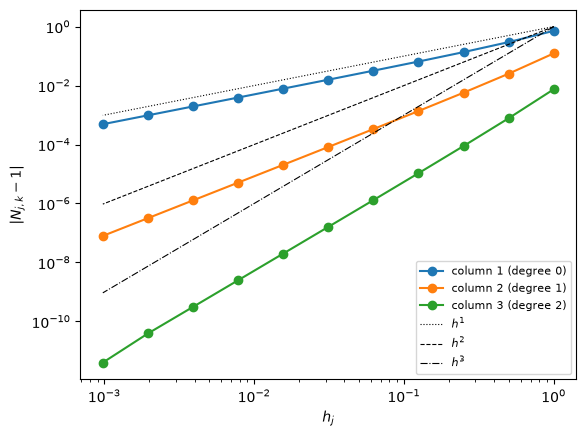

In [12]:
def f1(f: callable, m: int, n: int) -> np.ndarray:
    """
    Function that takes as input a function handle f and integers m, n ∈ N0.
    The output is a matrix N ∈ R(m+1)×(n+1) with entries Nj,k := pj,k(0), where j = 0,...,m,
    k = 0,...,n and pj,k is the polynomial of degree k that interpolates the data (hj+l,f(hj+l)),
    l= 0,...,k, where hi := 2-i
    """
    N = np.zeros((m + 1, n + 1))
    
    for j in range(m + 1):
        for k in range(n + 1):
            x_jk = 2.0 ** -(j + np.arange(k + 1))
            f_jk = f(x_jk)
            N[j, k] = routine(x_jk, f_jk)
    
    return N

m, n = 10, 2
N = f1(lambda h: (np.exp(h) - 1) / h, m, n) # Applying the routine to the function f(h) = (exp(h) - 1) / h
h = 2.0 ** -np.arange(m + 1)                # h_j for row j = 0..m

for k in range(n + 1):
    plt.loglog(h, np.abs(N[:, k] - 1), "o-", label=f"column {k + 1} (degree {k})")

# reference slopes
for p, ls in zip([1, 2, 3], ["k:", "k--", "k-."]):
    plt.loglog(h, h**p, ls, lw=0.8, label=f"$h^{p}$")

plt.xlabel("$h_j$")
plt.ylabel("$|N_{j,k} - 1|$")
plt.legend(fontsize=8)
plt.show()

**What convergence behavior do you observe for these 3 graphs?**

Okay so the $\lim_{h \to 0} f(h) = 1$ we represent here by creating an interpolation of various degrees (up to two) and evaluating it at zero, essentially cirumventing that we cannot directly evaluate f(0) (only e.g. via L'hopital, which gives us the limit of 1 as stated in the exercise).

In any way, now with N - 1 for all three degrees we want to see the error convergence as h approaches zero (to the left in the graph above). The first column converges like $O(h)$, the second column converges like $O(h^2)$, and the third column converges like $O(h^3)$.

The first column is a degree-0 polynomial, the second column is a degree-1 polynomial, and the third column is a degree-2 polynomial. What we can see is that the convergence error of the polynomial of degree k is $O(h^{k+1})$. Since each order is represented "perfectly" (i.e. the degree-0 polynomial is a constant, hence the constant part of e.g. the Taylor expansion of f is represented perfectly. So the error is only the next order term, which is $O(h^1)$, and so on for the other orders).

## 1.6. - Interpolating polynomials III

**Remark: Assuming that $x_3 = 3$ because it was missing in the exercise sheet.**

### 1.6.a) Compute the linear interpolation polynomial in x0, x3 and the cubic interpolation polynomial in all knots.

**Data:** $(x_0, f_0) = (0, 0)$, $(x_1, f_1) = (1, 1/2)$, $(x_2, f_2) = (2, 4/5)$, $(x_3, f_3) = (3, 9/10)$

**Lagrange basis polynomials:**

$$
\ell_0(x) = \frac{(x - 1)(x - 2)(x - 3)}{(0 - 1)(0 - 2)(0 - 3)} = -\frac{(x - 1)(x - 2)(x - 3)}{6}
$$

$$
\ell_1(x) = \frac{(x - 0)(x - 2)(x - 3)}{(1 - 0)(1 - 2)(1 - 3)} = \frac{x(x - 2)(x - 3)}{2}
$$

$$
\ell_2(x) = \frac{(x - 0)(x - 1)(x - 3)}{(2 - 0)(2 - 1)(2 - 3)} = -\frac{x(x - 1)(x - 3)}{2}
$$

$$
\ell_3(x) = \frac{(x - 0)(x - 1)(x - 2)}{(3 - 0)(3 - 1)(3 - 2)} = \frac{x(x - 1)(x - 2)}{6}
$$


**Interpolating polynomial in Lagrange form:**

$$
p_3(x) = \sum_{i=0}^{3} f_i \, \ell_i(x)
= 0 \cdot \ell_0(x) + \frac{1}{2} \cdot \frac{x(x - 2)(x - 3)}{2} + \frac{4}{5} \cdot \left(-\frac{x(x - 1)(x - 3)}{2}\right) + \frac{9}{10} \cdot \frac{x(x - 1)(x - 2)}{6}
$$

$$
= \frac{x(x - 2)(x - 3)}{4} - \frac{2x(x - 1)(x - 3)}{5} + \frac{3x(x - 1)(x - 2)}{20}
$$

Common denominator 20:

$$
= \frac{1}{20}\Big[5(x^3 - 5x^2 + 6x) - 8(x^3 - 4x^2 + 3x) + 3(x^3 - 3x^2 + 2x)\Big]
= \frac{1}{20}\Big[0 \cdot x^3 - 2x^2 + 12x\Big]
$$

$$
p_3(x) = \frac{6x - x^2}{10} = \frac{x(6 - x)}{10}
$$

**Remark:** The $x^3$ coefficient is gone, so the "cubic" interpolant is actually a quadratic; As in 1.4, the interpolant has degree maximum of 3.

**Check:** $p_3(0) = 0$, $p_3(1) = \tfrac{5}{10} = \tfrac{1}{2}$, $p_3(2) = \tfrac{8}{10} = \tfrac{4}{5}$, $p_3(3) = \tfrac{9}{10}$ 

**Linear interpolation polynomial** (I assume the description meant knots $x_0 = 0$, $x_3 = 3$ ??):

$$
p_1(x) = f_0 \frac{x - 3}{0 - 3} + f_3 \frac{x - 0}{3 - 0} = \frac{9}{10} \cdot \frac{x}{3} = \frac{3x}{10}
$$



### 1.6.b) Use both interpolation polynomials to compute approximations to integrate $f$ over $[0,3]$ and calculate the errors.

In [18]:
def cubic_polynomial(x: np.ndarray) -> np.ndarray:
    return x * (6 - x) / 10

def linear_polynomial(x: np.ndarray) -> np.ndarray:
    return (3 * x) / 10



### 1.6.b)

**Exact integral:** Using $\frac{x^2}{1+x^2} = 1 - \frac{1}{1+x^2}$,
$$
\int_0^3 \frac{x^2}{1+x^2}\,dx = \Big[x - \arctan x\Big]_0^3 = 3 - \arctan 3 \approx 1.750954
$$

**Linear:**
$$
\int_0^3 \frac{3x}{10}\,dx = \frac{3}{10} \cdot \frac{9}{2} = \frac{27}{20} = 1.35, \qquad \text{error} = 3 - \arctan 3 - 1.35 \approx 0.400954
$$

**Cubic:**
$$
\int_0^3 \frac{6x - x^2}{10}\,dx = \frac{1}{10}\Big[3x^2 - \tfrac{x^3}{3}\Big]_0^3 = \frac{27 - 9}{10} = 1.8, \qquad \text{error} = 3 - \arctan 3 - 1.8 \approx -0.049046
$$

